In [33]:

# ==========================================
# INTEGRATIVE TERMITE OPTIMIZATION PROJECT
# Environment Setup
# ==========================================

import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import scipy

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

print("\nEnvironment setup successful!")


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.4.6
Matplotlib: 3.10.0
Pandas: 2.2.3
SciPy: 1.16.3

Environment setup successful!


In [34]:
import numpy as np, math, time
def sphere(x): return np.sum(x*x, axis=-1)
def rastrigin(x): return 10*x.shape[-1] + np.sum(x*x - 10*np.cos(2*np.pi*x), axis=-1)
def rosenbrock(x):
    return np.sum(100*(x[...,1:]-x[...,:-1]**2)**2 + (1-x[...,:-1])**2, axis=-1)
def ackley(x):
    d=x.shape[-1]
    return -20*np.exp(-0.2*np.sqrt(np.sum(x*x,axis=-1)/d))-np.exp(np.sum(np.cos(2*np.pi*x),axis=-1)/d)+20+np.e
def levy_flight(shape,beta=1.5):
    sigma=(math.gamma(1+beta)*np.sin(np.pi*beta/2)/(math.gamma((1+beta)/2)*beta*2**((beta-1)/2)))**(1/beta)
    u=np.random.normal(0,sigma,size=shape)
    v=np.random.normal(0,1,size=shape)
    return u/(np.abs(v)**(1/beta)+1e-12)
def optimizer(objective, bounds, population_size=30, max_iter=300, memory_size=5, stagnation_window=20, diversity_threshold=0.03, seed=42):
    rng=np.random.default_rng(seed)
    low,high=bounds
    dim=len(low)
    X=rng.uniform(low,high,size=(population_size,dim))
    fit=np.asarray(objective(X),dtype=float)
    evals=population_size
    best_idx=np.argmin(fit); best=X[best_idx].copy(); bestfit=float(fit[best_idx])
    archive_X=np.empty((0,dim)); archive_f=np.empty(0)
    history=[]; divhist=[]; stagnant=0; last_best=bestfit
    for t in range(max_iter):
        order=np.argsort(fit)
        archive_X=np.vstack([archive_X,X[order[:memory_size]]])
        archive_f=np.concatenate([archive_f,fit[order[:memory_size]]])
        unique_idx=np.argsort(archive_f)[:memory_size]
        archive_X=archive_X[unique_idx]; archive_f=archive_f[unique_idx]
        weights=np.exp(-(archive_f-np.min(archive_f))/(np.std(archive_f)+1e-12))
        weights=weights/weights.sum()
        mem=archive_X[rng.choice(len(archive_X),p=weights)]
        diversity=float(np.mean(np.std(X,axis=0)/(high-low+1e-12)))
        if bestfit < last_best - 1e-12:
            stagnant=0; last_best=bestfit
        else: stagnant+=1
        stagnating=(stagnant>=stagnation_window) or (diversity<diversity_threshold)
        progress=t/max(1,max_iter-1)
        alpha=0.15+0.65*progress # queen attraction grows over time
        beta=0.15 # memory influence
        gamma=0.0 if not stagnating else 0.08
        r1=rng.random((population_size,dim))
        r2=rng.random((population_size,dim))
        noise=levy_flight((population_size,dim))
        step=(alpha*r1*(best-X) + beta*r2*(mem-X) + gamma*noise*(high-low))
        # modest Gaussian exploration always
        step += (0.01*(1-progress))*rng.normal(size=(population_size,dim))*(high-low)
        candidates=np.clip(X+step,low,high)
        cfit=np.asarray(objective(candidates),dtype=float); evals+=population_size
        improve=cfit<fit
        X[improve]=candidates[improve]; fit[improve]=cfit[improve]
        idx=np.argmin(fit)
        if fit[idx]<bestfit:
            bestfit=float(fit[idx]); best=X[idx].copy()
        history.append(bestfit); divhist.append(diversity)
    return {"best_position":best,"best_fitness":bestfit,"convergence":np.array(history),"diversity":np.array(divhist),"evaluations":evals}
for f,b in [(sphere,(-5.12,5.12)),(rastrigin,(-5.12,5.12)),(rosenbrock,(-5,10)),(ackley,(-32.768,32.768))]:
    r=optimizer(f,(np.full(10,b[0]),np.full(10,b[1])),max_iter=300,seed=42)
    print(f.__name__,r["best_fitness"],r["evaluations"])


sphere 0.35690522345731907 9030
rastrigin 36.48916075360905 9030
rosenbrock 199.87636795902833 9030
ackley 6.864393623395772 9030


In [35]:

# =====================================================
# STEP 1: BENCHMARK OPTIMIZATION FUNCTIONS
# =====================================================

import numpy as np

# 1. Sphere Function
def sphere(X):
    return np.sum(X**2, axis=1)


# 2. Rastrigin Function
def rastrigin(X):
    dimensions = X.shape[1]

    return (
        10 * dimensions
        + np.sum(
            X**2 - 10 * np.cos(2 * np.pi * X),
            axis=1
        )
    )


# 3. Rosenbrock Function
def rosenbrock(X):
    return np.sum(
        100 * (X[:, 1:] - X[:, :-1]**2)**2
        + (1 - X[:, :-1])**2,
        axis=1
    )


# 4. Ackley Function
def ackley(X):
    dimensions = X.shape[1]

    term1 = -20 * np.exp(
        -0.2 * np.sqrt(
            np.sum(X**2, axis=1) / dimensions
        )
    )

    term2 = -np.exp(
        np.sum(
            np.cos(2 * np.pi * X),
            axis=1
        ) / dimensions
    )

    return term1 + term2 + 20 + np.e


# Test all four functions
test_solution = np.zeros((1, 10))

print("Sphere:", sphere(test_solution)[0])
print("Rastrigin:", rastrigin(test_solution)[0])
print("Rosenbrock:", rosenbrock(test_solution)[0])
print("Ackley:", ackley(test_solution)[0])

print("\nBenchmark functions loaded successfully!")


Sphere: 0.0
Rastrigin: 0.0
Rosenbrock: 9.0
Ackley: 4.440892098500626e-16

Benchmark functions loaded successfully!


In [36]:

# ============================================================
# STEP 2: INTEGRATIVE TERMITE SWARM OPTIMIZATION (ITSO)
# ============================================================

import numpy as np
import math


def levy_flight(rng, shape, beta=1.5):
    """
    Generate Levy-flight steps using Mantegna's algorithm.
    """

    sigma = (
        math.gamma(1 + beta)
        * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = rng.normal(0, sigma, size=shape)
    v = rng.normal(0, 1, size=shape)

    return u / (np.abs(v) ** (1 / beta) + 1e-12)


def termite_optimizer(
    objective,
    bounds,
    population_size=30,
    max_iter=300,
    memory_size=10,
    stagnation_window=20,
    diversity_threshold=0.02,
    seed=42
):

    rng = np.random.default_rng(seed)

    # Search-space boundaries
    lower, upper = bounds

    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)

    dimensions = len(lower)
    search_range = upper - lower

    # ------------------------------------------------
    # 1. INITIALIZE TERMITE COLONY
    # ------------------------------------------------

    population = rng.uniform(
        lower,
        upper,
        size=(population_size, dimensions)
    )

    fitness = objective(population)

    evaluations = population_size

    best_index = np.argmin(fitness)

    global_best = population[best_index].copy()
    global_best_fitness = float(fitness[best_index])

    # Historical stigmergic memory
    archive_positions = np.empty((0, dimensions))
    archive_fitness = np.empty(0)

    convergence_history = []
    diversity_history = []
    exploration_history = []

    stagnation_counter = 0
    previous_best = global_best_fitness

    # ------------------------------------------------
    # 2. MAIN OPTIMIZATION LOOP
    # ------------------------------------------------

    for iteration in range(max_iter):

        progress = iteration / max(1, max_iter - 1)

        # --------------------------------------------
        # A. UPDATE STIGMERGIC MEMORY
        # --------------------------------------------

        sorted_indices = np.argsort(fitness)

        archive_positions = np.vstack([
            archive_positions,
            population[sorted_indices[:memory_size]]
        ])

        archive_fitness = np.concatenate([
            archive_fitness,
            fitness[sorted_indices[:memory_size]]
        ])

        # Retain only the best memory_size solutions
        archive_indices = np.argsort(archive_fitness)[
            :memory_size
        ]

        archive_positions = archive_positions[archive_indices]
        archive_fitness = archive_fitness[archive_indices]

        # Calculate memory selection probabilities
        fitness_spread = np.std(archive_fitness) + 1e-12

        memory_scores = -(
            archive_fitness - np.min(archive_fitness)
        ) / fitness_spread

        memory_weights = np.exp(
            np.clip(memory_scores, -50, 0)
        )

        memory_weights /= np.sum(memory_weights)

        # Each termite selects a promising memory
        selected_indices = rng.choice(
            len(archive_positions),
            size=population_size,
            p=memory_weights
        )

        selected_memory = archive_positions[selected_indices]

        # --------------------------------------------
        # B. POPULATION DIVERSITY
        # --------------------------------------------

        diversity = np.mean(
            np.std(population, axis=0)
            / (search_range + 1e-12)
        )

        # --------------------------------------------
        # C. STAGNATION DETECTION
        # --------------------------------------------

        if global_best_fitness < previous_best - 1e-12:
            stagnation_counter = 0
            previous_best = global_best_fitness
        else:
            stagnation_counter += 1

        stagnation_detected = (
            stagnation_counter >= stagnation_window
            or diversity < diversity_threshold
        )

        # --------------------------------------------
        # D. QUEEN-DRIVEN INTENSIFICATION
        # --------------------------------------------

        queen_strength = 0.20 + 0.60 * progress

        # --------------------------------------------
        # E. STIGMERGIC ATTRACTION
        # --------------------------------------------

        memory_strength = 0.20

        random_queen = rng.random(
            (population_size, dimensions)
        )

        random_memory = rng.random(
            (population_size, dimensions)
        )

        queen_movement = (
            queen_strength
            * random_queen
            * (global_best - population)
        )

        memory_movement = (
            memory_strength
            * random_memory
            * (selected_memory - population)
        )

        # --------------------------------------------
        # F. ALATE-INSPIRED EXPLORATION
        # --------------------------------------------

        alate_movement = np.zeros_like(population)

        if stagnation_detected:

            levy_steps = levy_flight(
                rng,
                (population_size, dimensions)
            )

            # Explore using a randomly selected
            # subset of the colony
            alate_mask = (
                rng.random(population_size) < 0.35
            )

            alate_movement = (
                0.08
                * levy_steps
                * search_range
                * alate_mask[:, None]
            )

        # Small background exploration
        background_noise = (
            0.01
            * (1 - progress)
            * rng.normal(
                size=(population_size, dimensions)
            )
            * search_range
        )

        # --------------------------------------------
        # G. UPDATE TERMITE POSITIONS
        # --------------------------------------------

        new_population = (
            population
            + queen_movement
            + memory_movement
            + alate_movement
            + background_noise
        )

        # Boundary handling
        new_population = np.clip(
            new_population,
            lower,
            upper
        )

        # Evaluate new candidate solutions
        new_fitness = objective(new_population)

        evaluations += population_size

        # --------------------------------------------
        # H. GREEDY SELECTION
        # --------------------------------------------

        improved = new_fitness < fitness

        population[improved] = new_population[improved]
        fitness[improved] = new_fitness[improved]

        # --------------------------------------------
        # I. ALATE REGENERATION
        # --------------------------------------------

        if stagnation_detected:

            restart_count = max(
                1,
                int(0.10 * population_size)
            )

            worst_indices = np.argsort(fitness)[
                -restart_count:
            ]

            regenerated = rng.uniform(
                lower,
                upper,
                size=(restart_count, dimensions)
            )

            regenerated_fitness = objective(regenerated)

            evaluations += restart_count

            population[worst_indices] = regenerated
            fitness[worst_indices] = regenerated_fitness

        # --------------------------------------------
        # J. UPDATE GLOBAL BEST
        # --------------------------------------------

        current_best_index = np.argmin(fitness)

        if fitness[current_best_index] < global_best_fitness:

            global_best = population[
                current_best_index
            ].copy()

            global_best_fitness = float(
                fitness[current_best_index]
            )

        # Record experimental measurements
        convergence_history.append(global_best_fitness)
        diversity_history.append(diversity)
        exploration_history.append(
            int(stagnation_detected)
        )

    # ------------------------------------------------
    # 3. RETURN EXPERIMENTAL RESULTS
    # ------------------------------------------------

    return {
        "best_position": global_best,
        "best_fitness": global_best_fitness,
        "convergence": np.array(convergence_history),
        "diversity": np.array(diversity_history),
        "exploration": np.array(exploration_history),
        "evaluations": evaluations
    }


print("ITSO algorithm implemented successfully!")


ITSO algorithm implemented successfully!


In [37]:

# =====================================================
# STEP 3: FIRST ITSO EXPERIMENT
# =====================================================

benchmark_tests = {
    "Sphere": {
        "function": sphere,
        "bounds": (-5.12, 5.12)
    },

    "Rastrigin": {
        "function": rastrigin,
        "bounds": (-5.12, 5.12)
    },

    "Rosenbrock": {
        "function": rosenbrock,
        "bounds": (-5, 10)
    },

    "Ackley": {
        "function": ackley,
        "bounds": (-32.768, 32.768)
    }
}

first_results = {}

for name, config in benchmark_tests.items():

    lower, upper = config["bounds"]

    result = termite_optimizer(
        objective=config["function"],
        bounds=(
            np.full(10, lower),
            np.full(10, upper)
        ),
        population_size=30,
        max_iter=300,
        seed=42
    )

    first_results[name] = result

    print("\nBenchmark:", name)
    print("Best Fitness:", result["best_fitness"])
    print("Best Position:", result["best_position"])
    print("Function Evaluations:", result["evaluations"])

print("\nFirst ITSO experiment completed!")



Benchmark: Sphere
Best Fitness: 2.8416150628081053e-06
Best Position: [-0.00053318 -0.00015716 -0.00025204  0.0011813  -0.00020558  0.00038358
  0.00032649 -0.00048476  0.00070873 -0.00020092]
Function Evaluations: 9264

Benchmark: Rastrigin
Best Fitness: 22.884690101209372
Best Position: [-1.98944784e+00  5.68364064e-04 -9.94808505e-01 -9.94711708e-01
  9.95813764e-01  9.94415217e-01 -2.98569118e+00 -9.94105682e-01
 -9.95509797e-01 -1.99003219e+00]
Function Evaluations: 9126

Benchmark: Rosenbrock
Best Fitness: 4.049581368240367
Best Position: [-0.99414271  0.99755121  0.999591    1.005366    1.01193957  1.0242667
  1.04981141  1.10097911  1.21010308  1.46606177]
Function Evaluations: 9249

Benchmark: Ackley
Best Fitness: 0.016672257346997288
Best Position: [-0.00328316 -0.00056145  0.00215629  0.00806716 -0.00036126  0.00251589
 -0.00468244 -0.00139565 -0.00674074  0.00041797]
Function Evaluations: 9297

First ITSO experiment completed!


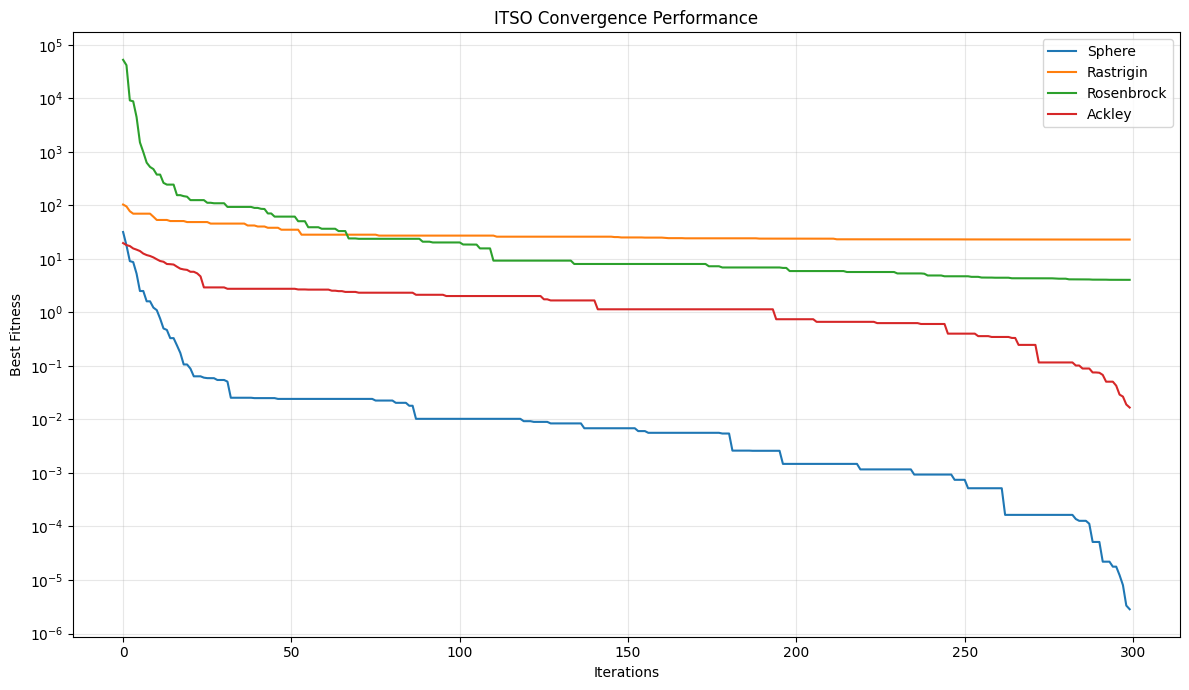

In [38]:

# =====================================================
# STEP 4: CONVERGENCE ANALYSIS
# =====================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for name, result in first_results.items():

    plt.plot(
        result["convergence"],
        label=name
    )

plt.yscale("symlog", linthresh=1e-8)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("ITSO Convergence Performance")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [39]:

# ============================================================
# STEP 5: PARTICLE SWARM OPTIMIZATION (PSO)
# ============================================================

def pso_optimizer(
    objective,
    bounds,
    population_size=30,
    max_iter=300,
    seed=42
):

    rng = np.random.default_rng(seed)

    lower, upper = map(
        lambda x: np.asarray(x, dtype=float),
        bounds
    )

    dimensions = len(lower)
    search_range = upper - lower

    # Initialize particles
    positions = rng.uniform(
        lower, upper,
        size=(population_size, dimensions)
    )

    velocities = rng.uniform(
        -0.1 * search_range,
        0.1 * search_range,
        size=(population_size, dimensions)
    )

    fitness = objective(positions)
    evaluations = population_size

    personal_best = positions.copy()
    personal_best_fitness = fitness.copy()

    best_index = np.argmin(fitness)

    global_best = positions[best_index].copy()
    global_best_fitness = float(fitness[best_index])

    convergence = []

    # Optimization loop
    for iteration in range(max_iter):

        w = 0.9 - 0.5 * iteration / max_iter

        r1 = rng.random(
            (population_size, dimensions)
        )

        r2 = rng.random(
            (population_size, dimensions)
        )

        # Velocity update
        velocities = (
            w * velocities
            + 2.0 * r1 * (personal_best - positions)
            + 2.0 * r2 * (global_best - positions)
        )

        velocities = np.clip(
            velocities,
            -0.2 * search_range,
            0.2 * search_range
        )

        # Position update
        new_positions = positions + velocities

        new_positions = np.clip(
            new_positions, lower, upper
        )

        new_fitness = objective(new_positions)
        evaluations += population_size

        # Personal best update
        improved = new_fitness < personal_best_fitness

        personal_best[improved] = new_positions[improved]
        personal_best_fitness[improved] = new_fitness[improved]

        # Global best update
        best_index = np.argmin(personal_best_fitness)

        if personal_best_fitness[best_index] < global_best_fitness:

            global_best = personal_best[best_index].copy()

            global_best_fitness = float(
                personal_best_fitness[best_index]
            )

        positions = new_positions
        fitness = new_fitness

        convergence.append(global_best_fitness)

    return {
        "best_position": global_best,
        "best_fitness": global_best_fitness,
        "convergence": np.array(convergence),
        "evaluations": evaluations
    }


print("PSO implementation completed!")


PSO implementation completed!


In [40]:

# ============================================================
# STEP 6: GENETIC ALGORITHM (GA)
# ============================================================

def ga_optimizer(
    objective,
    bounds,
    population_size=30,
    max_iter=300,
    mutation_rate=0.10,
    seed=42
):

    rng = np.random.default_rng(seed)

    lower, upper = map(
        lambda x: np.asarray(x, dtype=float),
        bounds
    )

    dimensions = len(lower)
    search_range = upper - lower

    # Initialize population
    population = rng.uniform(
        lower, upper,
        size=(population_size, dimensions)
    )

    fitness = objective(population)
    evaluations = population_size

    convergence = []

    for iteration in range(max_iter):

        # Sort population
        sorted_indices = np.argsort(fitness)

        # Preserve the best two individuals
        elite = population[sorted_indices[:2]].copy()

        new_population = [elite[0], elite[1]]

        # Tournament selection
        while len(new_population) < population_size:

            candidates = rng.integers(
                0, population_size, size=3
            )

            parent1 = population[
                candidates[np.argmin(fitness[candidates])]
            ]

            candidates = rng.integers(
                0, population_size, size=3
            )

            parent2 = population[
                candidates[np.argmin(fitness[candidates])]
            ]

            # Blend crossover
            alpha = rng.random(dimensions)

            child = (
                alpha * parent1
                + (1 - alpha) * parent2
            )

            # Gaussian mutation
            mutation_mask = (
                rng.random(dimensions) < mutation_rate
            )

            mutation = rng.normal(
                0,
                0.1 * search_range,
                size=dimensions
            )

            child = child + mutation_mask * mutation

            child = np.clip(child, lower, upper)

            new_population.append(child)

        population = np.array(new_population)

        fitness = objective(population)
        evaluations += population_size

        best_index = np.argmin(fitness)

        convergence.append(
            float(fitness[best_index])
        )

    best_index = np.argmin(fitness)

    return {
        "best_position": population[best_index].copy(),
        "best_fitness": float(fitness[best_index]),
        "convergence": np.array(convergence),
        "evaluations": evaluations
    }


print("GA implementation completed!")


GA implementation completed!


In [41]:

# ============================================================
# STEP 7: PRELIMINARY ALGORITHM COMPARISON
# ============================================================

algorithms = {
    "ITSO": termite_optimizer,
    "PSO": pso_optimizer,
    "GA": ga_optimizer
}

comparison_results = []

for function_name, config in benchmark_tests.items():

    lower, upper = config["bounds"]

    bounds = (
        np.full(10, lower),
        np.full(10, upper)
    )

    print("\n" + "=" * 45)
    print("BENCHMARK:", function_name)
    print("=" * 45)

    for algorithm_name, algorithm in algorithms.items():

        result = algorithm(
            objective=config["function"],
            bounds=bounds,
            population_size=30,
            max_iter=300,
            seed=42
        )

        comparison_results.append({
            "Benchmark": function_name,
            "Algorithm": algorithm_name,
            "Best Fitness": result["best_fitness"],
            "Evaluations": result["evaluations"]
        })

        print(
            algorithm_name,
            "-> Best Fitness:",
            result["best_fitness"]
        )

comparison_df = pd.DataFrame(comparison_results)

print("\nFINAL PRELIMINARY COMPARISON")
display(comparison_df)



BENCHMARK: Sphere
ITSO -> Best Fitness: 2.8416150628081053e-06
PSO -> Best Fitness: 8.165292904402602e-09
GA -> Best Fitness: 2.857769500037215e-05

BENCHMARK: Rastrigin
ITSO -> Best Fitness: 22.884690101209372
PSO -> Best Fitness: 7.979172438512734
GA -> Best Fitness: 1.1175428876807132

BENCHMARK: Rosenbrock
ITSO -> Best Fitness: 4.049581368240367
PSO -> Best Fitness: 6.3882832829092315
GA -> Best Fitness: 7.111864782792011

BENCHMARK: Ackley
ITSO -> Best Fitness: 0.016672257346997288
PSO -> Best Fitness: 0.00022821540453721312
GA -> Best Fitness: 0.056506487034170494

FINAL PRELIMINARY COMPARISON


,Benchmark,Algorithm,Best Fitness,Evaluations
0,Sphere,ITSO,2.841615e-06,9264
1,Sphere,PSO,8.165293e-09,9030
2,Sphere,GA,2.857770e-05,9030
3,Rastrigin,ITSO,2.288469e+01,9126
4,Rastrigin,PSO,7.979172e+00,9030
5,Rastrigin,GA,1.117543e+00,9030
6,Rosenbrock,ITSO,4.049581e+00,9249
7,Rosenbrock,PSO,6.388283e+00,9030
8,Rosenbrock,GA,7.111865e+00,9030
9,Ackley,ITSO,1.667226e-02,9297


In [10]:

# ============================================================
# STEP 8: REPEATED EXPERIMENTS (30 INDEPENDENT RUNS)
# ============================================================

import time

NUM_RUNS = 30

all_results = []
all_convergence = []

for function_name, config in benchmark_tests.items():

    lower, upper = config["bounds"]

    bounds = (
        np.full(10, lower),
        np.full(10, upper)
    )

    for algorithm_name, algorithm in algorithms.items():

        print(
            f"\nRunning {algorithm_name} on {function_name}..."
        )

        for run in range(NUM_RUNS):

            start_time = time.perf_counter()

            result = algorithm(
                objective=config["function"],
                bounds=bounds,
                population_size=30,
                max_iter=300,
                seed=1000 + run
            )

            elapsed = time.perf_counter() - start_time

            all_results.append({
                "Benchmark": function_name,
                "Algorithm": algorithm_name,
                "Run": run + 1,
                "Best Fitness": result["best_fitness"],
                "Evaluations": result["evaluations"],
                "Runtime": elapsed
            })

            all_convergence.append({
                "Benchmark": function_name,
                "Algorithm": algorithm_name,
                "Run": run + 1,
                "Convergence": result["convergence"]
            })

results_df = pd.DataFrame(all_results)

summary_df = (
    results_df
    .groupby(["Benchmark", "Algorithm"])["Best Fitness"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

summary_df.columns = [
    "Benchmark",
    "Algorithm",
    "Mean Fitness",
    "Std Fitness",
    "Best Fitness",
    "Worst Fitness"
]

print("\n30-RUN EXPERIMENT COMPLETED")

display(summary_df)



Running ITSO on Sphere...

Running PSO on Sphere...

Running GA on Sphere...

Running ITSO on Rastrigin...

Running PSO on Rastrigin...

Running GA on Rastrigin...

Running ITSO on Rosenbrock...

Running PSO on Rosenbrock...

Running GA on Rosenbrock...

Running ITSO on Ackley...

Running PSO on Ackley...

Running GA on Ackley...

30-RUN EXPERIMENT COMPLETED


,Benchmark,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness
0,Ackley,GA,5.319140e-02,2.156478e-02,1.970479e-02,1.021577e-01
1,Ackley,ITSO,1.395439e-02,3.508521e-03,8.676959e-03,2.075464e-02
2,Ackley,PSO,6.322211e-04,6.362111e-04,6.174295e-05,3.528142e-03
3,Rastrigin,GA,3.880483e-01,5.292044e-01,1.139504e-02,2.041345e+00
4,Rastrigin,ITSO,1.432797e+01,6.826574e+00,3.980375e+00,3.183886e+01
5,Rastrigin,PSO,6.926387e+00,3.662510e+00,9.958222e-01,1.890511e+01
6,Rosenbrock,GA,1.779182e+01,2.407126e+01,2.418437e+00,8.037413e+01
7,Rosenbrock,ITSO,7.433288e+00,2.026296e+01,6.632206e-03,8.337956e+01
8,Rosenbrock,PSO,4.215309e+01,1.812173e+02,8.111936e-01,9.973258e+02
9,Sphere,GA,4.417568e-05,3.572144e-05,1.171430e-05,1.507857e-04


In [11]:

# ============================================================
# STEP 9: SAVE EXPERIMENTAL RESULTS
# ============================================================

import os

os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/experimental_results.csv",
    index=False
)

summary_df.to_csv(
    "results/summary_results.csv",
    index=False
)

print("Experimental results saved successfully!")

print("Files:")
print("- results/experimental_results.csv")
print("- results/summary_results.csv")


Experimental results saved successfully!
Files:
- results/experimental_results.csv
- results/summary_results.csv


In [12]:

# =====================================================
# PHASE 4: EXPERIMENTAL RESULT INSPECTION
# =====================================================

print("===== FINAL PERFORMANCE SUMMARY =====")
display(summary_df)

print("\n===== FUNCTION EVALUATION SUMMARY =====")

evaluation_summary = (
    results_df
    .groupby(["Benchmark", "Algorithm"])["Evaluations"]
    .agg(["mean", "min", "max"])
    .reset_index()
)

display(evaluation_summary)

print("\n===== EXECUTION TIME SUMMARY =====")

runtime_summary = (
    results_df
    .groupby(["Benchmark", "Algorithm"])["Runtime"]
    .agg(["mean", "std"])
    .reset_index()
)

display(runtime_summary)


===== FINAL PERFORMANCE SUMMARY =====


,Benchmark,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness
0,Ackley,GA,5.319140e-02,2.156478e-02,1.970479e-02,1.021577e-01
1,Ackley,ITSO,1.395439e-02,3.508521e-03,8.676959e-03,2.075464e-02
2,Ackley,PSO,6.322211e-04,6.362111e-04,6.174295e-05,3.528142e-03
3,Rastrigin,GA,3.880483e-01,5.292044e-01,1.139504e-02,2.041345e+00
4,Rastrigin,ITSO,1.432797e+01,6.826574e+00,3.980375e+00,3.183886e+01
5,Rastrigin,PSO,6.926387e+00,3.662510e+00,9.958222e-01,1.890511e+01
6,Rosenbrock,GA,1.779182e+01,2.407126e+01,2.418437e+00,8.037413e+01
7,Rosenbrock,ITSO,7.433288e+00,2.026296e+01,6.632206e-03,8.337956e+01
8,Rosenbrock,PSO,4.215309e+01,1.812173e+02,8.111936e-01,9.973258e+02
9,Sphere,GA,4.417568e-05,3.572144e-05,1.171430e-05,1.507857e-04



===== FUNCTION EVALUATION SUMMARY =====


,Benchmark,Algorithm,mean,min,max
0,Ackley,GA,9030.0,9030,9030
1,Ackley,ITSO,9335.6,9255,9492
2,Ackley,PSO,9030.0,9030,9030
3,Rastrigin,GA,9030.0,9030,9030
4,Rastrigin,ITSO,9167.5,9057,9336
5,Rastrigin,PSO,9030.0,9030,9030
6,Rosenbrock,GA,9030.0,9030,9030
7,Rosenbrock,ITSO,9304.3,9192,9414
8,Rosenbrock,PSO,9030.0,9030,9030
9,Sphere,GA,9030.0,9030,9030



===== EXECUTION TIME SUMMARY =====


,Benchmark,Algorithm,mean,std
0,Ackley,GA,0.686741,0.149277
1,Ackley,ITSO,0.107436,0.007677
2,Ackley,PSO,0.029755,0.003239
3,Rastrigin,GA,0.679491,0.183877
4,Rastrigin,ITSO,0.121404,0.026358
5,Rastrigin,PSO,0.024907,0.002976
6,Rosenbrock,GA,0.640027,0.115844
7,Rosenbrock,ITSO,0.125702,0.025204
8,Rosenbrock,PSO,0.040678,0.002530
9,Sphere,GA,0.673459,0.150816


In [13]:
import numpy as np
import pandas as pd

checkpoints = [0, 49, 99, 149, 199, 249, 299]
convergence_rows = []

for record in all_convergence:
    curve = np.asarray(record["Convergence"])

    for iteration in checkpoints:
        index = min(iteration, len(curve) - 1)

        convergence_rows.append({
            "Benchmark": record["Benchmark"],
            "Algorithm": record["Algorithm"],
            "Run": record["Run"],
            "Iteration": iteration + 1,
            "Fitness": curve[index]
        })

convergence_df = pd.DataFrame(convergence_rows)

convergence_summary = (
    convergence_df
    .groupby(["Benchmark", "Algorithm", "Iteration"])["Fitness"]
    .agg(["mean", "std"])
    .reset_index()
)

print(convergence_summary.to_string(index=False))

 Benchmark Algorithm  Iteration         mean          std
    Ackley        GA          1 1.836463e+01 8.640143e-01
    Ackley        GA         50 1.640302e+00 5.945207e-01
    Ackley        GA        100 4.624813e-01 3.123855e-01
    Ackley        GA        150 1.900263e-01 9.182345e-02
    Ackley        GA        200 1.122568e-01 4.627701e-02
    Ackley        GA        250 8.042636e-02 3.521678e-02
    Ackley        GA        300 5.319140e-02 2.156478e-02
    Ackley      ITSO          1 1.930104e+01 4.497160e-01
    Ackley      ITSO         50 2.516195e+00 2.618482e-01
    Ackley      ITSO        100 1.946712e+00 2.427956e-01
    Ackley      ITSO        150 1.504297e+00 1.797592e-01
    Ackley      ITSO        200 9.507291e-01 1.502335e-01
    Ackley      ITSO        250 3.759221e-01 6.757167e-02
    Ackley      ITSO        300 1.395439e-02 3.508521e-03
    Ackley       PSO          1 1.816527e+01 6.254354e-01
    Ackley       PSO         50 7.246572e+00 9.550434e-01
    Ackley    

In [14]:
import numpy as np
import math

def levy_flight(rng, shape, beta=1.5):
    """Generate Levy-flight steps using Mantegna's algorithm."""
    sigma_u = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = rng.normal(0, sigma_u, shape)
    v = rng.normal(0, 1, shape)

    return u / (np.abs(v) ** (1 / beta) + 1e-12)


def termite_optimizer_ablation(
    objective,
    bounds,
    population_size=30,
    max_iter=300,
    memory_size=10,
    stagnation_window=20,
    diversity_threshold=0.02,
    seed=42,
    use_memory=True,
    use_alates=True,
    use_queen=True
):
    """
    Reconstructed Integrative Termite Swarm Optimization.

    Mechanisms:
    1. Stigmergic memory: archive-based attraction.
    2. Alate dispersal: Levy-flight exploration.
    3. Queen adaptation: adaptive movement coefficient.
    """

    rng = np.random.default_rng(seed)

    lower, upper = bounds
    dimensions = len(lower)
    search_range = upper - lower

    # Initialize population
    population = rng.uniform(
        lower, upper, (population_size, dimensions)
    )

    fitness = objective(population)
    evaluations = population_size

    best_idx = np.argmin(fitness)
    global_best = population[best_idx].copy()
    global_best_fitness = float(fitness[best_idx])

    convergence = [global_best_fitness]
    diversity_history = []
    exploration_history = []

    # Initialize stigmergic archive
    archive_positions = population.copy()
    archive_fitness = fitness.copy()

    stagnation_counter = 0

    for iteration in range(max_iter):

        # Calculate population diversity
        diversity = np.mean(
            np.std(population, axis=0) / (search_range + 1e-12)
        )
        diversity_history.append(float(diversity))

        # Detect stagnation
        stagnation = (
            stagnation_counter >= stagnation_window
            or diversity < diversity_threshold
        )

        # Adaptive queen movement coefficient
        if use_queen:
            queen_coefficient = (
                0.2 + 0.6 * iteration / max(1, max_iter - 1)
            )
        else:
            queen_coefficient = 0.5

        # Decreasing background exploration noise
        noise_scale = 0.05 * (
            1 - iteration / max_iter
        )

        # Generate candidate population
        candidates = population.copy()

        for i in range(population_size):

            movement = queen_coefficient * rng.random(
                dimensions
            ) * (global_best - population[i])

            # Stigmergic memory attraction
            if use_memory:
                archive_min = np.min(archive_fitness)
                archive_scale = np.std(archive_fitness) + 1e-12

                weights = np.exp(
                    -(archive_fitness - archive_min) / archive_scale
                )
                weights /= np.sum(weights)

                memory_idx = rng.choice(
                    len(archive_positions), p=weights
                )

                memory_target = archive_positions[memory_idx]

                memory_attraction = (
                    0.2 * rng.random(dimensions)
                    * (memory_target - population[i])
                )
            else:
                memory_attraction = np.zeros(dimensions)

            # Background noise
            noise = (
                noise_scale
                * search_range
                * rng.normal(size=dimensions)
            )

            candidates[i] = (
                population[i]
                + movement
                + memory_attraction
                + noise
            )

        # Alate dispersal through Levy flights
        if use_alates and stagnation:

            number_of_alates = max(
                1, int(0.35 * population_size)
            )

            alate_indices = rng.choice(
                population_size,
                size=number_of_alates,
                replace=False
            )

            levy_steps = levy_flight(
                rng, (number_of_alates, dimensions)
            )

            candidates[alate_indices] += (
                0.08
                * levy_steps
                * search_range
            )

        exploration_history.append(
            bool(use_alates and stagnation)
        )

        # Keep candidates within search bounds
        candidates = np.clip(candidates, lower, upper)

        candidate_fitness = objective(candidates)
        evaluations += population_size

        # Greedy selection
        improved = candidate_fitness < fitness

        population[improved] = candidates[improved]
        fitness[improved] = candidate_fitness[improved]

        # Update global best
        current_idx = np.argmin(fitness)

        if fitness[current_idx] < global_best_fitness:
            global_best_fitness = float(fitness[current_idx])
            global_best = population[current_idx].copy()
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        # Update archive
        if use_memory:
            combined_positions = np.vstack(
                [archive_positions, population]
            )
            combined_fitness = np.concatenate(
                [archive_fitness, fitness]
            )

            selected = np.argsort(combined_fitness)

            archive_positions = combined_positions[selected].copy()[:memory_size]
            archive_fitness = combined_fitness[selected].copy()[:memory_size]

        # Restart worst 10% on stagnation
        if stagnation:

            restart_count = max(
                1, int(0.10 * population_size)
            )

            worst_indices = np.argsort(fitness)[
                -restart_count:
            ]

            population[worst_indices] = rng.uniform(
                lower,
                upper,
                (restart_count, dimensions)
            )

            restarted_fitness = objective(
                population[worst_indices]
            )

            evaluations += restart_count
            fitness[worst_indices] = restarted_fitness

            stagnation_counter = 0

            # Check whether a restarted candidate improves global best
            restart_best_idx = np.argmin(restarted_fitness)

            if restarted_fitness[restart_best_idx] < global_best_fitness:
                global_best_fitness = float(
                    restarted_fitness[restart_best_idx]
                )
                global_best = population[
                    worst_indices[restart_best_idx]
                ].copy()

        convergence.append(global_best_fitness)

    return {
        "best_position": global_best,
        "best_fitness": global_best_fitness,
        "convergence": np.array(convergence),
        "diversity": np.array(diversity_history),
        "exploration": np.array(exploration_history),
        "evaluations": evaluations
    }

print("Reconstructed ITSO implementation ready.")

Reconstructed ITSO implementation ready.


In [15]:

ablation_variants = {
    "Full ITSO": {
        "use_memory": True,
        "use_alates": True,
        "use_queen": True
    },
    "Without Memory": {
        "use_memory": False,
        "use_alates": True,
        "use_queen": True
    },
    "Without Alates": {
        "use_memory": True,
        "use_alates": False,
        "use_queen": True
    },
    "Without Queen": {
        "use_memory": True,
        "use_alates": True,
        "use_queen": False
    }
}

print("Ablation configurations ready.")

for name, settings in ablation_variants.items():
    print(name, settings)


Ablation configurations ready.
Full ITSO {'use_memory': True, 'use_alates': True, 'use_queen': True}
Without Memory {'use_memory': False, 'use_alates': True, 'use_queen': True}
Without Alates {'use_memory': True, 'use_alates': False, 'use_queen': True}
Without Queen {'use_memory': True, 'use_alates': True, 'use_queen': False}


In [16]:

import numpy as np
import math

def levy_flight(rng, shape, beta=1.5):
    sigma_u = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = rng.normal(0, sigma_u, shape)
    v = rng.normal(0, 1, shape)

    return u / (np.abs(v) ** (1 / beta) + 1e-12)


def termite_optimizer_ablation(
    objective,
    bounds,
    population_size=30,
    max_iter=300,
    memory_size=10,
    stagnation_window=20,
    diversity_threshold=0.02,
    seed=42,
    use_memory=True,
    use_alates=True,
    use_queen=True
):

    rng = np.random.default_rng(seed)

    lower, upper = bounds
    dimensions = len(lower)
    search_range = upper - lower

    population = rng.uniform(
        lower, upper, (population_size, dimensions)
    )

    fitness = objective(population)
    evaluations = population_size

    best_idx = np.argmin(fitness)
    global_best = population[best_idx].copy()
    global_best_fitness = float(fitness[best_idx])

    archive_positions = population.copy()
    archive_fitness = fitness.copy()

    convergence = [global_best_fitness]
    diversity_history = []
    exploration_history = []

    stagnation_counter = 0

    for iteration in range(max_iter):

        diversity = np.mean(
            np.std(population, axis=0) / (search_range + 1e-12)
        )
        diversity_history.append(float(diversity))

        stagnation = (
            stagnation_counter >= stagnation_window
            or diversity < diversity_threshold
        )

        if use_queen:
            queen_coefficient = (
                0.2 + 0.6 * iteration / max(1, max_iter - 1)
            )
        else:
            queen_coefficient = 0.5

        noise_scale = 0.05 * (1 - iteration / max_iter)

        # Vectorized movement towards global best
        movement = (
            queen_coefficient
            * rng.random((population_size, dimensions))
            * (global_best - population)
        )

        # Vectorized stigmergic memory
        if use_memory:

            archive_min = np.min(archive_fitness)
            archive_scale = np.std(archive_fitness) + 1e-12

            weights = np.exp(
                -(archive_fitness - archive_min) / archive_scale
            )
            weights /= np.sum(weights)

            memory_indices = rng.choice(
                len(archive_positions),
                size=population_size,
                p=weights
            )

            memory_targets = archive_positions[memory_indices]

            memory_attraction = (
                0.2
                * rng.random((population_size, dimensions))
                * (memory_targets - population)
            )

        else:
            memory_attraction = np.zeros_like(population)

        noise = (
            noise_scale
            * search_range
            * rng.normal(size=(population_size, dimensions))
        )

        candidates = (
            population + movement + memory_attraction + noise
        )

        # Alate dispersal
        if use_alates and stagnation:

            number_of_alates = max(
                1, int(0.35 * population_size)
            )

            alate_indices = rng.choice(
                population_size,
                size=number_of_alates,
                replace=False
            )

            candidates[alate_indices] += (
                0.08
                * levy_flight(
                    rng, (number_of_alates, dimensions)
                )
                * search_range
            )

            exploration_history.append(True)

        else:
            exploration_history.append(False)

        candidates = np.clip(candidates, lower, upper)

        candidate_fitness = objective(candidates)
        evaluations += population_size

        improved = candidate_fitness < fitness

        population[improved] = candidates[improved]
        fitness[improved] = candidate_fitness[improved]

        current_idx = np.argmin(fitness)

        if fitness[current_idx] < global_best_fitness:
            global_best_fitness = float(fitness[current_idx])
            global_best = population[current_idx].copy()
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        # Update archive
        if use_memory:

            combined_positions = np.vstack(
                [archive_positions, population]
            )
            combined_fitness = np.concatenate(
                [archive_fitness, fitness]
            )

            selected = np.argsort(combined_fitness)[:memory_size]

            archive_positions = combined_positions[selected].copy()
            archive_fitness = combined_fitness[selected].copy()

        # Population restart
        if stagnation:

            restart_count = max(
                1, int(0.10 * population_size)
            )

            worst_indices = np.argsort(fitness)[-restart_count:]

            population[worst_indices] = rng.uniform(
                lower,
                upper,
                (restart_count, dimensions)
            )

            restarted_fitness = objective(
                population[worst_indices]
            )

            evaluations += restart_count
            fitness[worst_indices] = restarted_fitness

            stagnation_counter = 0

            restart_best_idx = np.argmin(restarted_fitness)

            if restarted_fitness[restart_best_idx] < global_best_fitness:
                global_best_fitness = float(
                    restarted_fitness[restart_best_idx]
                )
                global_best = population[
                    worst_indices[restart_best_idx]
                ].copy()

        convergence.append(global_best_fitness)

    return {
        "best_position": global_best,
        "best_fitness": global_best_fitness,
        "convergence": convergence,
        "diversity": diversity_history,
        "exploration": exploration_history,
        "evaluations": evaluations
    }


print("Optimized ITSO implementation ready.")


Optimized ITSO implementation ready.


In [17]:

test_config = benchmark_tests["Sphere"]

test_bounds = (
    np.full(10, test_config["bounds"][0]),
    np.full(10, test_config["bounds"][1])
)

test_result = termite_optimizer_ablation(
    objective=test_config["function"],
    bounds=test_bounds,
    population_size=30,
    max_iter=50,
    seed=42
)

print("Test completed")
print("Best fitness:", test_result["best_fitness"])
print("Evaluations:", test_result["evaluations"])


Test completed
Best fitness: 0.004185150038216518
Evaluations: 1545


In [18]:

import pandas as pd
import time
import os

NUM_RUNS = 30
POPULATION_SIZE = 30
MAX_ITERATIONS = 300
DIMENSIONS = 10

# Start with a fresh result list
ablation_results = []

total_runs = (
    len(benchmark_tests)
    * len(ablation_variants)
    * NUM_RUNS
)

completed = 0
experiment_start = time.perf_counter()

for function_name, config in benchmark_tests.items():

    bounds = (
        np.full(DIMENSIONS, config["bounds"][0]),
        np.full(DIMENSIONS, config["bounds"][1])
    )

    for variant_name, settings in ablation_variants.items():

        for run in range(NUM_RUNS):

            start_time = time.perf_counter()

            result = termite_optimizer_ablation(
                objective=config["function"],
                bounds=bounds,
                population_size=POPULATION_SIZE,
                max_iter=MAX_ITERATIONS,
                seed=1000 + run,
                **settings
            )

            elapsed = time.perf_counter() - start_time

            ablation_results.append({
                "Benchmark": function_name,
                "Configuration": variant_name,
                "Run": run + 1,
                "Best Fitness": result["best_fitness"],
                "Evaluations": result["evaluations"],
                "Runtime": elapsed
            })

            completed += 1

        print(
            f"{function_name} | {variant_name} | "
            f"Completed {completed}/{total_runs}"
        )

ablation_df = pd.DataFrame(ablation_results)

print("\nExperiment completed.")
print("Total runs:", len(ablation_df))
print(
    "Total time:",
    round(time.perf_counter() - experiment_start, 2),
    "seconds"
)


Sphere | Full ITSO | Completed 30/480
Sphere | Without Memory | Completed 60/480
Sphere | Without Alates | Completed 90/480
Sphere | Without Queen | Completed 120/480
Rastrigin | Full ITSO | Completed 150/480
Rastrigin | Without Memory | Completed 180/480
Rastrigin | Without Alates | Completed 210/480
Rastrigin | Without Queen | Completed 240/480
Rosenbrock | Full ITSO | Completed 270/480
Rosenbrock | Without Memory | Completed 300/480
Rosenbrock | Without Alates | Completed 330/480
Rosenbrock | Without Queen | Completed 360/480
Ackley | Full ITSO | Completed 390/480
Ackley | Without Memory | Completed 420/480
Ackley | Without Alates | Completed 450/480
Ackley | Without Queen | Completed 480/480

Experiment completed.
Total runs: 480
Total time: 39.57 seconds


In [19]:

ablation_summary = (
    ablation_df
    .groupby(["Benchmark", "Configuration"])["Best Fitness"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

ablation_summary.columns = [
    "Benchmark",
    "Configuration",
    "Mean Fitness",
    "Std Fitness",
    "Best Fitness",
    "Worst Fitness"
]

display(ablation_summary)

os.makedirs("results", exist_ok=True)

ablation_df.to_csv(
    "results/ablation_experimental_results.csv",
    index=False
)

ablation_summary.to_csv(
    "results/ablation_summary.csv",
    index=False
)

print("Both CSV files saved successfully.")


,Benchmark,Configuration,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness
0,Ackley,Full ITSO,0.088639,0.022797,0.046325,0.139060
1,Ackley,Without Alates,0.087531,0.022176,0.040243,0.140107
2,Ackley,Without Memory,0.115413,0.027806,0.054022,0.189086
3,Ackley,Without Queen,0.114960,0.032770,0.069039,0.201179
4,Rastrigin,Full ITSO,6.924856,2.767417,3.010892,14.956814
5,Rastrigin,Without Alates,7.649966,3.126666,2.001695,15.939700
6,Rastrigin,Without Memory,7.512393,3.523579,3.025218,19.017579
7,Rastrigin,Without Queen,8.014142,4.353946,2.014538,19.979087
8,Rosenbrock,Full ITSO,9.494141,10.419509,1.678701,63.863804
9,Rosenbrock,Without Alates,7.594092,1.301963,1.626821,9.415384


Both CSV files saved successfully.


In [20]:

from scipy.stats import wilcoxon
import pandas as pd
import numpy as np

mechanisms = [
    "Without Memory",
    "Without Alates",
    "Without Queen"
]

statistical_results = []

for benchmark in ablation_df["Benchmark"].unique():

    full = (
        ablation_df[
            (ablation_df["Benchmark"] == benchmark) &
            (ablation_df["Configuration"] == "Full ITSO")
        ][["Run", "Best Fitness"]]
        .rename(columns={"Best Fitness": "Full"})
    )

    for variant in mechanisms:

        reduced = (
            ablation_df[
                (ablation_df["Benchmark"] == benchmark) &
                (ablation_df["Configuration"] == variant)
            ][["Run", "Best Fitness"]]
            .rename(columns={"Best Fitness": "Variant"})
        )

        paired = full.merge(reduced, on="Run")

        # Positive difference means Full ITSO performed better
        differences = paired["Variant"] - paired["Full"]

        if np.allclose(differences, 0):
            statistic, p_value = 0.0, 1.0
        else:
            statistic, p_value = wilcoxon(
                paired["Full"],
                paired["Variant"],
                alternative="two-sided"
            )

        statistical_results.append({
            "Benchmark": benchmark,
            "Comparison": f"Full ITSO vs {variant}",
            "Median Difference (Variant - Full)": np.median(differences),
            "Wilcoxon Statistic": statistic,
            "P-value": p_value
        })

statistical_df = pd.DataFrame(statistical_results)

print(statistical_df.to_string(index=False))


 Benchmark                  Comparison  Median Difference (Variant - Full)  Wilcoxon Statistic  P-value
    Sphere Full ITSO vs Without Memory                            0.000043               105.0 0.007612
    Sphere Full ITSO vs Without Alates                           -0.000025               139.0 0.054922
    Sphere  Full ITSO vs Without Queen                            0.000029               151.0 0.096102
 Rastrigin Full ITSO vs Without Memory                           -0.514898               220.0 0.807830
 Rastrigin Full ITSO vs Without Alates                            0.981074               174.0 0.236652
 Rastrigin  Full ITSO vs Without Queen                            1.019450               176.0 0.253436
Rosenbrock Full ITSO vs Without Memory                            0.115212               224.0 0.871208
Rosenbrock Full ITSO vs Without Alates                           -0.030898               211.0 0.670181
Rosenbrock  Full ITSO vs Without Queen                          

In [21]:

evaluation_summary = (
    ablation_df
    .groupby(["Benchmark", "Configuration"])["Evaluations"]
    .agg(["mean", "min", "max"])
    .reset_index()
)

print(evaluation_summary.to_string(index=False))


 Benchmark  Configuration   mean  min  max
    Ackley      Full ITSO 9141.3 9135 9150
    Ackley Without Alates 9141.6 9135 9147
    Ackley Without Memory 9113.5 9105 9120
    Ackley  Without Queen 9129.0 9123 9138
 Rastrigin      Full ITSO 9052.1 9045 9060
 Rastrigin Without Alates 9052.5 9048 9060
 Rastrigin Without Memory 9051.3 9045 9063
 Rastrigin  Without Queen 9053.4 9048 9060
Rosenbrock      Full ITSO 9124.7 9102 9138
Rosenbrock Without Alates 9125.8 9108 9135
Rosenbrock Without Memory 9099.9 9081 9111
Rosenbrock  Without Queen 9111.3 9090 9126
    Sphere      Full ITSO 9143.5 9135 9150
    Sphere Without Alates 9143.3 9138 9147
    Sphere Without Memory 9116.5 9111 9123
    Sphere  Without Queen 9131.0 9123 9138


CELL 21


In [50]:

# ============================================================
# STAGE C: CORRECTED FIXED-BUDGET ITSO OPTIMIZER
# Cell 21
# ============================================================

import numpy as np
import math


# ------------------------------------------------------------
# Levy Flight: Mantegna's Algorithm
# ------------------------------------------------------------

def levy_flight(rng, shape, beta=1.5):

    sigma_u = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = rng.normal(0, sigma_u, shape)
    v = rng.normal(0, 1, shape)

    return u / (np.abs(v) ** (1 / beta) + 1e-12)


# ------------------------------------------------------------
# Fixed-Budget ITSO Optimizer
# ------------------------------------------------------------

def termite_optimizer_fixed_budget(
    objective,
    bounds,
    population_size=30,
    max_iter=400,
    evaluation_budget=9150,
    memory_size=10,
    stagnation_window=20,
    diversity_threshold=0.02,
    seed=42,
    use_memory=True,
    use_alates=True,
    use_queen=True
):

    rng = np.random.default_rng(seed)

    lower, upper = bounds
    dimensions = len(lower)
    search_range = upper - lower

    if evaluation_budget < population_size:
        raise ValueError(
            "Evaluation budget must be at least population_size."
        )

    # --------------------------------------------------------
    # 1. Initialize population
    # --------------------------------------------------------

    population = rng.uniform(
        lower, upper, (population_size, dimensions)
    )

    fitness = objective(population)
    evaluations = population_size

    best_idx = np.argmin(fitness)

    global_best = population[best_idx].copy()
    global_best_fitness = float(fitness[best_idx])

    archive_positions = population.copy()
    archive_fitness = fitness.copy()

    convergence = [global_best_fitness]
    stagnation_counter = 0

    # --------------------------------------------------------
    # 2. Main optimization loop
    # --------------------------------------------------------

    for iteration in range(max_iter):

        # Stop if another complete population evaluation
        # would exceed the evaluation budget.

        if evaluations + population_size > evaluation_budget:
            break

        # ----------------------------------------------------
        # 3. Progress based on actual evaluation consumption
        # ----------------------------------------------------

        progress = min(
            1.0,
            max(
                0.0,
                (evaluations - population_size)
                / max(1, evaluation_budget - population_size)
            )
        )

        # ----------------------------------------------------
        # 4. Calculate population diversity and stagnation
        # ----------------------------------------------------

        diversity = np.mean(
            np.std(population, axis=0)
            / (search_range + 1e-12)
        )

        stagnation = (
            stagnation_counter >= stagnation_window
            or diversity < diversity_threshold
        )

        # ----------------------------------------------------
        # 5. Queen-driven adaptive exploitation
        # ----------------------------------------------------

        if use_queen:
            queen_coefficient = 0.20 + 0.60 * progress
        else:
            queen_coefficient = 0.0

        movement = (
            queen_coefficient
            * rng.random((population_size, dimensions))
            * (global_best - population)
        )

        # ----------------------------------------------------
        # 6. Stigmergic trail-based memory
        # ----------------------------------------------------

        if use_memory:

            archive_min = np.min(archive_fitness)
            archive_scale = np.std(archive_fitness) + 1e-12

            weights = np.exp(
                -(archive_fitness - archive_min) / archive_scale
            )

            weights /= np.sum(weights)

            memory_indices = rng.choice(
                len(archive_positions),
                size=population_size,
                p=weights
            )

            memory_targets = archive_positions[memory_indices]

            memory_attraction = (
                0.20
                * rng.random((population_size, dimensions))
                * (memory_targets - population)
            )

        else:

            memory_attraction = np.zeros_like(population)

        # ----------------------------------------------------
        # 7. Background noise with budget-based decay
        # ----------------------------------------------------

        noise_scale = 0.05 * (1.0 - progress)

        noise = (
            noise_scale
            * search_range
            * rng.normal(size=(population_size, dimensions))
        )

        candidates = (
            population
            + movement
            + memory_attraction
            + noise
        )

        # ----------------------------------------------------
        # 8. Alate dispersal using Levy flights
        # ----------------------------------------------------

        if use_alates and stagnation:

            number_of_alates = max(
                1, int(0.35 * population_size)
            )

            alate_indices = rng.choice(
                population_size,
                size=number_of_alates,
                replace=False
            )

            candidates[alate_indices] += (
                0.08
                * levy_flight(
                    rng,
                    (number_of_alates, dimensions)
                )
                * search_range
            )

        candidates = np.clip(candidates, lower, upper)

        # ----------------------------------------------------
        # 9. Evaluate candidates
        # ----------------------------------------------------

        candidate_fitness = objective(candidates)
        evaluations += population_size

        # ----------------------------------------------------
        # 10. Greedy selection
        # ----------------------------------------------------

        improved = candidate_fitness < fitness

        population[improved] = candidates[improved]
        fitness[improved] = candidate_fitness[improved]

        current_idx = np.argmin(fitness)

        if fitness[current_idx] < global_best_fitness:

            global_best_fitness = float(fitness[current_idx])
            global_best = population[current_idx].copy()

            stagnation_counter = 0

        else:

            stagnation_counter += 1

        # ----------------------------------------------------
        # 11. Update stigmergic memory archive
        # ----------------------------------------------------

        if use_memory:

            combined_positions = np.vstack(
                [archive_positions, population]
            )

            combined_fitness = np.concatenate(
                [archive_fitness, fitness]
            )

            selected = np.argsort(combined_fitness)[:memory_size]

            archive_positions = combined_positions[selected].copy()
            archive_fitness = combined_fitness[selected].copy()

        # ----------------------------------------------------
        # 12. Restart worst individuals during stagnation
        # ----------------------------------------------------

        if stagnation:

            restart_count = max(
                1, int(0.10 * population_size)
            )

            if evaluations + restart_count <= evaluation_budget:

                worst_indices = np.argsort(fitness)[-restart_count:]

                population[worst_indices] = rng.uniform(
                    lower,
                    upper,
                    (restart_count, dimensions)
                )

                restarted_fitness = objective(
                    population[worst_indices]
                )

                evaluations += restart_count

                fitness[worst_indices] = restarted_fitness

                restart_best_idx = np.argmin(restarted_fitness)

                if (
                    restarted_fitness[restart_best_idx]
                    < global_best_fitness
                ):

                    global_best_fitness = float(
                        restarted_fitness[restart_best_idx]
                    )

                    global_best = population[
                        worst_indices[restart_best_idx]
                    ].copy()

            stagnation_counter = 0

        # ----------------------------------------------------
        # 13. Record convergence
        # ----------------------------------------------------

        convergence.append(global_best_fitness)

    # --------------------------------------------------------
    # 14. Return results
    # --------------------------------------------------------

    return {
        "best_position": global_best,
        "best_fitness": global_best_fitness,
        "convergence": convergence,
        "evaluations": evaluations
    }


print("Corrected fixed-budget ITSO implementation ready.")



Corrected fixed-budget ITSO implementation ready.


In [23]:

test_config = benchmark_tests["Sphere"]

test_bounds = (
    np.full(10, test_config["bounds"][0]),
    np.full(10, test_config["bounds"][1])
)

test_result = termite_optimizer_fixed_budget(
    objective=test_config["function"],
    bounds=test_bounds,
    population_size=30,
    max_iter=400,
    evaluation_budget=9150,
    seed=42
)

print("Test fitness:", test_result["best_fitness"])
print("Function evaluations:", test_result["evaluations"])
print("Budget:", 9150)

assert test_result["evaluations"] <= 9150

print("Budget validation passed.")


Test fitness: 0.03438489744657991
Function evaluations: 9147
Budget: 9150
Budget validation passed.


In [24]:

import pandas as pd
import time

NUM_RUNS = 30
POPULATION_SIZE = 30
MAX_ITERATIONS = 400
EVALUATION_BUDGET = 9150
DIMENSIONS = 10

fixed_budget_results = []

total_runs = (
    len(benchmark_tests)
    * len(ablation_variants)
    * NUM_RUNS
)

completed = 0
start_time = time.perf_counter()

for function_name, config in benchmark_tests.items():

    bounds = (
        np.full(DIMENSIONS, config["bounds"][0]),
        np.full(DIMENSIONS, config["bounds"][1])
    )

    for variant_name, settings in ablation_variants.items():

        for run in range(NUM_RUNS):

            run_start = time.perf_counter()

            result = termite_optimizer_fixed_budget(
                objective=config["function"],
                bounds=bounds,
                population_size=POPULATION_SIZE,
                max_iter=MAX_ITERATIONS,
                evaluation_budget=EVALUATION_BUDGET,
                seed=1000 + run,
                **settings
            )

            elapsed = time.perf_counter() - run_start

            fixed_budget_results.append({
                "Benchmark": function_name,
                "Configuration": variant_name,
                "Run": run + 1,
                "Best Fitness": result["best_fitness"],
                "Evaluations": result["evaluations"],
                "Runtime": elapsed
            })

            completed += 1

        print(
            f"{function_name} | {variant_name} | "
            f"{completed}/{total_runs} completed"
        )

fixed_budget_df = pd.DataFrame(fixed_budget_results)

print("\nAll experiments completed.")
print("Total runs:", len(fixed_budget_df))
print(
    "Total time:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)

assert fixed_budget_df["Evaluations"].max() <= EVALUATION_BUDGET


Sphere | Full ITSO | 30/480 completed
Sphere | Without Memory | 60/480 completed
Sphere | Without Alates | 90/480 completed
Sphere | Without Queen | 120/480 completed
Rastrigin | Full ITSO | 150/480 completed
Rastrigin | Without Memory | 180/480 completed
Rastrigin | Without Alates | 210/480 completed
Rastrigin | Without Queen | 240/480 completed
Rosenbrock | Full ITSO | 270/480 completed
Rosenbrock | Without Memory | 300/480 completed
Rosenbrock | Without Alates | 330/480 completed
Rosenbrock | Without Queen | 360/480 completed
Ackley | Full ITSO | 390/480 completed
Ackley | Without Memory | 420/480 completed
Ackley | Without Alates | 450/480 completed
Ackley | Without Queen | 480/480 completed

All experiments completed.
Total runs: 480
Total time: 39.06 seconds


In [25]:
import os
import pandas as pd

os.makedirs("results", exist_ok=True)

# Calculate summaries to avoid NameError if cells are run out of order
fixed_budget_summary = (
    fixed_budget_df
    .groupby(["Benchmark", "Configuration"])["Best Fitness"]
    .agg(["mean", "std", "min", "max"]
    ).reset_index()
)
fixed_budget_summary.columns = [
    "Benchmark",
    "Configuration",
    "Mean Fitness",
    "Std Fitness",
    "Best Fitness",
    "Worst Fitness"
]

budget_audit = (
    fixed_budget_df
    .groupby(["Benchmark", "Configuration"])["Evaluations"]
    .agg(["mean", "min", "max"]
    ).reset_index()
)

# Save files
fixed_budget_df.to_csv(
    "results/fixed_budget_ablation_runs.csv",
    index=False
)

fixed_budget_summary.to_csv(
    "results/fixed_budget_ablation_summary.csv",
    index=False
)

budget_audit.to_csv(
    "results/fixed_budget_evaluation_audit.csv",
    index=False
)

print("All fixed-budget results saved successfully.")

All fixed-budget results saved successfully.


In [26]:
print("Results available:", "fixed_budget_df" in globals())

if "fixed_budget_df" in globals():
    print("Total experiment runs:", len(fixed_budget_df))
    display(fixed_budget_df.head())

Results available: True
Total experiment runs: 480


,Benchmark,Configuration,Run,Best Fitness,Evaluations,Runtime
0,Sphere,Full ITSO,1,0.036053,9144,0.088247
1,Sphere,Full ITSO,2,0.037363,9144,0.076386
2,Sphere,Full ITSO,3,0.035204,9150,0.080495
3,Sphere,Full ITSO,4,0.043913,9144,0.081671
4,Sphere,Full ITSO,5,0.028375,9144,0.076390


In [27]:
fixed_budget_summary = (
    fixed_budget_df
    .groupby(["Benchmark", "Configuration"])["Best Fitness"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

fixed_budget_summary.columns = [
    "Benchmark",
    "Configuration",
    "Mean Fitness",
    "Std Fitness",
    "Best Fitness",
    "Worst Fitness"
]

display(fixed_budget_summary)

,Benchmark,Configuration,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness
0,Ackley,Full ITSO,2.941794,0.292393,2.289909,3.434385
1,Ackley,Without Alates,2.899743,0.244548,2.278625,3.331308
2,Ackley,Without Memory,3.045581,0.245144,2.527464,3.464722
3,Ackley,Without Queen,3.020623,0.278934,2.418677,3.491830
4,Rastrigin,Full ITSO,16.887950,4.356011,7.904301,26.116887
5,Rastrigin,Without Alates,17.488112,4.340288,10.083897,26.107525
6,Rastrigin,Without Memory,23.216636,4.015948,12.263762,31.195955
7,Rastrigin,Without Queen,20.108078,5.055835,10.367780,30.385634
8,Rosenbrock,Full ITSO,24.026680,24.286462,10.799924,97.825908
9,Rosenbrock,Without Alates,22.386777,20.233390,11.679085,89.911341


In [28]:
import os

os.makedirs("results", exist_ok=True)

fixed_budget_df.to_csv(
    "results/fixed_budget_ablation_runs.csv",
    index=False
)

fixed_budget_summary.to_csv(
    "results/fixed_budget_ablation_summary.csv",
    index=False
)

budget_audit = (
    fixed_budget_df
    .groupby(["Benchmark", "Configuration"])["Evaluations"]
    .agg(["mean", "min", "max"])
    .reset_index()
)

budget_audit.to_csv(
    "results/fixed_budget_evaluation_audit.csv",
    index=False
)

print("All three CSV files saved successfully.")

All three CSV files saved successfully.


In [29]:
budget_audit = (
    fixed_budget_df
    .groupby(["Benchmark", "Configuration"])["Evaluations"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

display(budget_audit)

,Benchmark,Configuration,mean,std,min,max
0,Ackley,Full ITSO,9142.0,3.280034,9135,9147
1,Ackley,Without Alates,9143.1,3.707867,9135,9150
2,Ackley,Without Memory,9144.6,8.049845,9123,9150
3,Ackley,Without Queen,9138.2,3.933937,9132,9150
4,Rastrigin,Full ITSO,9140.1,10.949256,9123,9150
5,Rastrigin,Without Alates,9138.8,11.683764,9123,9150
6,Rastrigin,Without Memory,9138.5,12.232658,9123,9150
7,Rastrigin,Without Queen,9136.1,12.368899,9123,9150
8,Rosenbrock,Full ITSO,9131.9,8.281054,9123,9150
9,Rosenbrock,Without Alates,9132.1,8.683516,9123,9150


In [30]:
from scipy.stats import wilcoxon
import pandas as pd
import numpy as np

comparisons = []

mechanisms = [
    "Without Memory",
    "Without Alates",
    "Without Queen"
]

for benchmark in fixed_budget_df["Benchmark"].unique():

    full = fixed_budget_df[
        (fixed_budget_df["Benchmark"] == benchmark) &
        (fixed_budget_df["Configuration"] == "Full ITSO")
    ][["Run", "Best Fitness"]].rename(
        columns={"Best Fitness": "Full"}
    )

    for variant in mechanisms:

        reduced = fixed_budget_df[
            (fixed_budget_df["Benchmark"] == benchmark) &
            (fixed_budget_df["Configuration"] == variant)
        ][["Run", "Best Fitness"]].rename(
            columns={"Best Fitness": "Variant"}
        )

        paired = full.merge(reduced, on="Run")

        differences = paired["Variant"] - paired["Full"]

        if np.allclose(differences, 0):
            statistic, p_value = 0.0, 1.0
        else:
            statistic, p_value = wilcoxon(
                paired["Full"],
                paired["Variant"],
                alternative="two-sided"
            )

        comparisons.append({
            "Benchmark": benchmark,
            "Mechanism Removed": variant,
            "Median Difference": np.median(differences),
            "P-value": p_value
        })

stats_df = pd.DataFrame(comparisons)

# Holm multiple-comparison correction
p_values = stats_df["P-value"].to_numpy()
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))

running_max = 0

for rank, index in enumerate(order):
    corrected = (len(p_values) - rank) * p_values[index]
    running_max = max(running_max, corrected)
    adjusted[index] = min(running_max, 1.0)

stats_df["Holm Adjusted P"] = adjusted
stats_df["Significant"] = stats_df["Holm Adjusted P"] < 0.05

display(stats_df)

,Benchmark,Mechanism Removed,Median Difference,P-value,Holm Adjusted P,Significant
0,Sphere,Without Memory,0.001189,7.765688e-01,1.000000,False
1,Sphere,Without Alates,-0.001553,2.988441e-01,1.000000,False
2,Sphere,Without Queen,-0.004740,8.406548e-02,0.840655,False
3,Rastrigin,Without Memory,5.602507,9.983778e-07,0.000012,True
4,Rastrigin,Without Alates,0.014106,6.850471e-01,1.000000,False
5,Rastrigin,Without Queen,4.163206,4.031794e-03,0.044350,True
6,Rosenbrock,Without Memory,-0.418504,2.206468e-01,1.000000,False
7,Rosenbrock,Without Alates,0.569698,6.120056e-01,1.000000,False
8,Rosenbrock,Without Queen,-0.481172,3.598779e-01,1.000000,False
9,Ackley,Without Memory,0.106420,1.241345e-01,1.000000,False


In [31]:
stats_df.to_csv(
    "results/fixed_budget_statistical_tests.csv",
    index=False
)

print("Statistical results saved.")

Statistical results saved.


In [32]:

import os
import zipfile

results_dir = "/content/results"
os.makedirs(results_dir, exist_ok=True)

required_files = [
    "experimental_results.csv",
    "summary_results.csv",
    "ablation_experimental_results.csv",
    "ablation_summary.csv",
    "fixed_budget_ablation_runs.csv",
    "fixed_budget_ablation_summary.csv",
    "fixed_budget_evaluation_audit.csv",
    "fixed_budget_statistical_tests.csv"
]

print("Checking result files:")

for filename in required_files:
    path = os.path.join(results_dir, filename)
    print(filename, ":", "Available" if os.path.exists(path) else "Missing")

zip_path = "/content/termite_experimental_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in required_files:
        path = os.path.join(results_dir, filename)
        if os.path.exists(path):
            zipf.write(path, arcname=filename)

print("\nResults archive created:", zip_path)

from google.colab import files
files.download(zip_path)


Checking result files:
experimental_results.csv : Available
summary_results.csv : Available
ablation_experimental_results.csv : Available
ablation_summary.csv : Available
fixed_budget_ablation_runs.csv : Available
fixed_budget_ablation_summary.csv : Available
fixed_budget_evaluation_audit.csv : Available
fixed_budget_statistical_tests.csv : Available

Results archive created: /content/termite_experimental_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:

# STEP 1: Check existing experimental results

required_variables = [
    "benchmark_tests",
    "termite_optimizer",
    "pso_optimizer",
    "ga_optimizer",
    "all_results",
    "all_convergence",
    "results_df",
    "summary_df",
    "ablation_df",
    "ablation_summary",
    "fixed_budget_df",
    "fixed_budget_summary",
    "stats_df"
]

print("EXPERIMENTAL RESULTS CHECK")
print("=" * 45)

for variable in required_variables:
    exists = variable in globals()
    print(f"{variable}: {'AVAILABLE' if exists else 'MISSING'}")

print("\nDATASET SIZES")
print("=" * 45)

for variable in [
    "all_results",
    "all_convergence",
    "results_df",
    "ablation_df",
    "fixed_budget_df"
]:
    if variable in globals():
        obj = globals()[variable]
        print(f"{variable}: {len(obj)} records")

print("\nCHECK COMPLETE")


EXPERIMENTAL RESULTS CHECK
benchmark_tests: AVAILABLE
termite_optimizer: AVAILABLE
pso_optimizer: AVAILABLE
ga_optimizer: AVAILABLE
all_results: AVAILABLE
all_convergence: AVAILABLE
results_df: AVAILABLE
summary_df: AVAILABLE
ablation_df: AVAILABLE
ablation_summary: AVAILABLE
fixed_budget_df: AVAILABLE
fixed_budget_summary: AVAILABLE
stats_df: AVAILABLE

DATASET SIZES
all_results: 360 records
all_convergence: 360 records
results_df: 360 records
ablation_df: 480 records
fixed_budget_df: 480 records

CHECK COMPLETE


In [43]:

# STEP 2: Inspect convergence history structure

print("FIRST CONVERGENCE RECORD")
print("=" * 45)

print("Record type:", type(all_convergence[0]))
print("Available keys:", all_convergence[0].keys())

for key, value in all_convergence[0].items():
    print(f"\n{key}:")
    print("Type:", type(value))

    if hasattr(value, "shape"):
        print("Shape:", value.shape)

    if hasattr(value, "__len__") and not isinstance(value, str):
        print("Length:", len(value))

    print("Sample:", str(value)[:300])


print("\nCONVERGENCE HISTORY COUNTS")
print("=" * 45)

for algorithm in ["ITSO", "PSO", "GA"]:
    count = sum(
        1 for record in all_convergence
        if record["Algorithm"] == algorithm
    )
    print(f"{algorithm}: {count} histories")


print("\nINSPECTION COMPLETE")


FIRST CONVERGENCE RECORD
Record type: <class 'dict'>
Available keys: dict_keys(['Benchmark', 'Algorithm', 'Run', 'Convergence'])

Benchmark:
Type: <class 'str'>
Sample: Sphere

Algorithm:
Type: <class 'str'>
Sample: ITSO

Run:
Type: <class 'int'>
Sample: 1

Convergence:
Type: <class 'numpy.ndarray'>
Shape: (300,)
Length: 300
Sample: [2.97085410e+01 1.96897376e+01 1.15362273e+01 7.33591881e+00
 5.26580467e+00 3.42876366e+00 2.51046173e+00 2.39216945e+00
 1.82067551e+00 1.17476972e+00 7.82252576e-01 7.82252576e-01
 7.82252576e-01 5.18059703e-01 5.18059703e-01 4.10008084e-01
 3.97823324e-01 2.76653756e-01 2.76653756e-01 1.97982490

CONVERGENCE HISTORY COUNTS
ITSO: 120 histories
PSO: 120 histories
GA: 120 histories

INSPECTION COMPLETE


In [44]:

# STEP 3: Export complete convergence histories

import os
import zipfile
import numpy as np
import pandas as pd

os.makedirs("results", exist_ok=True)

convergence_rows = []

for record in all_convergence:
    curve = np.asarray(record["Convergence"])

    for iteration, fitness in enumerate(curve, start=1):
        convergence_rows.append({
            "Benchmark": record["Benchmark"],
            "Algorithm": record["Algorithm"],
            "Run": record["Run"],
            "Iteration": iteration,
            "Fitness": float(fitness)
        })

convergence_full_df = pd.DataFrame(convergence_rows)

# Save the complete CSV
csv_path = "results/full_convergence_histories.csv"
convergence_full_df.to_csv(csv_path, index=False)

# Create a separate backup ZIP
zip_path = "full_convergence_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(csv_path, arcname="full_convergence_histories.csv")

print("EXPORT COMPLETE")
print("=" * 45)
print("Total rows:", len(convergence_full_df))
print("Expected rows:", 108000)
print("Columns:", list(convergence_full_df.columns))
print("Benchmarks:", convergence_full_df["Benchmark"].nunique())
print("Algorithms:", convergence_full_df["Algorithm"].nunique())
print("Runs:", convergence_full_df.groupby(
    ["Benchmark", "Algorithm"]
)["Run"].nunique().to_dict())
print("\nCSV saved:", csv_path)
print("ZIP backup saved:", zip_path)

print("\nPreview:")
display(convergence_full_df.head())



EXPORT COMPLETE
Total rows: 108000
Expected rows: 108000
Columns: ['Benchmark', 'Algorithm', 'Run', 'Iteration', 'Fitness']
Benchmarks: 4
Algorithms: 3
Runs: {('Ackley', 'GA'): 30, ('Ackley', 'ITSO'): 30, ('Ackley', 'PSO'): 30, ('Rastrigin', 'GA'): 30, ('Rastrigin', 'ITSO'): 30, ('Rastrigin', 'PSO'): 30, ('Rosenbrock', 'GA'): 30, ('Rosenbrock', 'ITSO'): 30, ('Rosenbrock', 'PSO'): 30, ('Sphere', 'GA'): 30, ('Sphere', 'ITSO'): 30, ('Sphere', 'PSO'): 30}

CSV saved: results/full_convergence_histories.csv
ZIP backup saved: full_convergence_backup.zip

Preview:


,Benchmark,Algorithm,Run,Iteration,Fitness
0,Sphere,ITSO,1,1,29.708541
1,Sphere,ITSO,1,2,19.689738
2,Sphere,ITSO,1,3,11.536227
3,Sphere,ITSO,1,4,7.335919
4,Sphere,ITSO,1,5,5.265805


In [45]:

# STEP 4A: Preserve original Stage C results

import os
import pandas as pd

# Create independent copies in memory
fixed_budget_df_original = fixed_budget_df.copy(deep=True)
fixed_budget_summary_original = fixed_budget_summary.copy(deep=True)
stats_df_original = stats_df.copy(deep=True)

# Save original results separately
os.makedirs("results/stage_c_original", exist_ok=True)

fixed_budget_df_original.to_csv(
    "results/stage_c_original/original_runs.csv",
    index=False
)

fixed_budget_summary_original.to_csv(
    "results/stage_c_original/original_summary.csv",
    index=False
)

stats_df_original.to_csv(
    "results/stage_c_original/original_statistics.csv",
    index=False
)

print("ORIGINAL STAGE C BACKUP COMPLETE")
print("=" * 45)
print("Original runs:", len(fixed_budget_df_original))
print("Original summary rows:", len(fixed_budget_summary_original))
print("Original statistical tests:", len(stats_df_original))
print("Original results preserved in memory and CSV files.")


ORIGINAL STAGE C BACKUP COMPLETE
Original runs: 480
Original summary rows: 16
Original statistical tests: 12
Original results preserved in memory and CSV files.


In [46]:

# STEP 4B: Corrected fixed-budget ITSO optimizer

import numpy as np
import math

def levy_flight(rng, shape, beta=1.5):
    sigma_u = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = rng.normal(0, sigma_u, shape)
    v = rng.normal(0, 1, shape)

    return u / (np.abs(v) ** (1 / beta) + 1e-12)


def termite_optimizer_fixed_budget(
    objective,
    bounds,
    population_size=30,
    max_iter=400,
    evaluation_budget=9150,
    memory_size=10,
    stagnation_window=20,
    diversity_threshold=0.02,
    seed=42,
    use_memory=True,
    use_alates=True,
    use_queen=True
):
    rng = np.random.default_rng(seed)

    lower, upper = bounds
    dimensions = len(lower)
    search_range = upper - lower

    if evaluation_budget < population_size:
        raise ValueError(
            "Evaluation budget must be at least population_size."
        )

    # Initial population
    population = rng.uniform(
        lower, upper, (population_size, dimensions)
    )

    fitness = objective(population)
    evaluations = population_size

    best_idx = np.argmin(fitness)
    global_best = population[best_idx].copy()
    global_best_fitness = float(fitness[best_idx])

    archive_positions = population.copy()
    archive_fitness = fitness.copy()

    convergence = [global_best_fitness]
    stagnation_counter = 0

    for iteration in range(max_iter):

        # Stop if another complete population evaluation is unaffordable
        if evaluations + population_size > evaluation_budget:
            break

        # Progress is based on consumed evaluation budget
        progress = min(
            1.0,
            max(
                0.0,
                (evaluations - population_size)
                / max(1, evaluation_budget - population_size)
            )
        )

        diversity = np.mean(
            np.std(population, axis=0)
            / (search_range + 1e-12)
        )

        stagnation = (
            stagnation_counter >= stagnation_window
            or diversity < diversity_threshold
        )

        # Queen mechanism
        if use_queen:
            queen_coefficient = 0.20 + 0.60 * progress
        else:
            queen_coefficient = 0.0

        movement = (
            queen_coefficient
            * rng.random((population_size, dimensions))
            * (global_best - population)
        )

        # Stigmergic memory mechanism
        if use_memory:
            archive_min = np.min(archive_fitness)
            archive_scale = np.std(archive_fitness) + 1e-12

            weights = np.exp(
                -(archive_fitness - archive_min) / archive_scale
            )
            weights /= np.sum(weights)

            memory_indices = rng.choice(
                len(archive_positions),
                size=population_size,
                p=weights
            )

            memory_targets = archive_positions[memory_indices]

            memory_attraction = (
                0.20
                * rng.random((population_size, dimensions))
                * (memory_targets - population)
            )
        else:
            memory_attraction = np.zeros_like(population)

        # Background noise schedule
        noise_scale = 0.05 * (1.0 - progress)

        noise = (
            noise_scale
            * search_range
            * rng.normal(size=(population_size, dimensions))
        )

        candidates = (
            population
            + movement
            + memory_attraction
            + noise
        )

        # Alate dispersal mechanism
        if use_alates and stagnation:

            number_of_alates = max(
                1, int(0.35 * population_size)
            )

            alate_indices = rng.choice(
                population_size,
                size=number_of_alates,
                replace=False
            )

            candidates[alate_indices] += (
                0.08
                * levy_flight(
                    rng, (number_of_alates, dimensions)
                )
                * search_range
            )

        candidates = np.clip(candidates, lower, upper)

        candidate_fitness = objective(candidates)
        evaluations += population_size

        # Greedy selection
        improved = candidate_fitness < fitness

        population[improved] = candidates[improved]
        fitness[improved] = candidate_fitness[improved]

        current_idx = np.argmin(fitness)

        if fitness[current_idx] < global_best_fitness:
            global_best_fitness = float(fitness[current_idx])
            global_best = population[current_idx].copy()
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        # Update memory archive
        if use_memory:
            combined_positions = np.vstack(
                [archive_positions, population]
            )
            combined_fitness = np.concatenate(
                [archive_fitness, fitness]
            )

            selected = np.argsort(combined_fitness)[:memory_size]

            archive_positions = combined_positions[selected].copy()
            archive_fitness = combined_fitness[selected].copy()

        # Restart worst 10% if the remaining budget permits
        if stagnation:

            restart_count = max(
                1, int(0.10 * population_size)
            )

            if evaluations + restart_count <= evaluation_budget:

                worst_indices = np.argsort(fitness)[-restart_count:]

                population[worst_indices] = rng.uniform(
                    lower,
                    upper,
                    (restart_count, dimensions)
                )

                restarted_fitness = objective(
                    population[worst_indices]
                )

                evaluations += restart_count
                fitness[worst_indices] = restarted_fitness

                restart_best_idx = np.argmin(restarted_fitness)

                if restarted_fitness[restart_best_idx] < global_best_fitness:
                    global_best_fitness = float(
                        restarted_fitness[restart_best_idx]
                    )
                    global_best = population[
                        worst_indices[restart_best_idx]
                    ].copy()

            stagnation_counter = 0

        convergence.append(global_best_fitness)

    return {
        "best_position": global_best,
        "best_fitness": global_best_fitness,
        "convergence": convergence,
        "evaluations": evaluations
    }


print("Corrected fixed-budget ITSO implementation ready.")


Corrected fixed-budget ITSO implementation ready.


In [47]:

# STEP 4C: Validate corrected optimizer

test_bounds = (
    np.full(10, -5.12),
    np.full(10, 5.12)
)

test_result = termite_optimizer_fixed_budget(
    objective=sphere,
    bounds=test_bounds,
    population_size=30,
    max_iter=400,
    evaluation_budget=9150,
    seed=42
)

print("VALIDATION RESULTS")
print("=" * 40)
print("Best fitness:", test_result["best_fitness"])
print("Evaluations:", test_result["evaluations"])
print("Iterations:", len(test_result["convergence"]) - 1)
print("Convergence length:", len(test_result["convergence"]))

assert test_result["evaluations"] <= 9150
assert test_result["evaluations"] >= 30
assert len(test_result["convergence"]) > 1
assert np.isfinite(test_result["best_fitness"])

print("\nAll validation checks passed.")


VALIDATION RESULTS
Best fitness: 0.00011624405510211157
Evaluations: 9147
Iterations: 300
Convergence length: 301

All validation checks passed.


In [48]:

# STEP 5: Test all four Stage C configurations

configurations = {
    "Full ITSO": {
        "use_memory": True,
        "use_alates": True,
        "use_queen": True
    },
    "Without Alates": {
        "use_memory": True,
        "use_alates": False,
        "use_queen": True
    },
    "Without Memory": {
        "use_memory": False,
        "use_alates": True,
        "use_queen": True
    },
    "Without Queen": {
        "use_memory": True,
        "use_alates": True,
        "use_queen": False
    }
}

print("CONFIGURATION VALIDATION")
print("=" * 55)

for name, config in configurations.items():

    result = termite_optimizer_fixed_budget(
        objective=sphere,
        bounds=test_bounds,
        population_size=30,
        max_iter=400,
        evaluation_budget=9150,
        seed=42,
        **config
    )

    print(f"\n{name}")
    print("Best fitness:", result["best_fitness"])
    print("Evaluations:", result["evaluations"])
    print("Iterations:", len(result["convergence"]) - 1)

    assert result["evaluations"] <= 9150
    assert np.isfinite(result["best_fitness"])

print("\nAll four configurations passed.")


CONFIGURATION VALIDATION

Full ITSO
Best fitness: 0.00011624405510211157
Evaluations: 9147
Iterations: 300

Without Alates
Best fitness: 6.683903254715365e-05
Evaluations: 9141
Iterations: 300

Without Memory
Best fitness: 0.0001663952238239756
Evaluations: 9144
Iterations: 301

Without Queen
Best fitness: 0.0008221986625669218
Evaluations: 9123
Iterations: 302

All four configurations passed.


In [49]:

import pandas as pd
import time

NUM_RUNS = 30
POPULATION_SIZE = 30
MAX_ITERATIONS = 400
EVALUATION_BUDGET = 9150
DIMENSIONS = 10

fixed_budget_results = []

total_runs = (
    len(benchmark_tests)
    * len(ablation_variants)
    * NUM_RUNS
)

completed = 0
start_time = time.perf_counter()

for function_name, config in benchmark_tests.items():

    bounds = (
        np.full(DIMENSIONS, config["bounds"][0]),
        np.full(DIMENSIONS, config["bounds"][1])
    )

    for variant_name, settings in ablation_variants.items():

        for run in range(NUM_RUNS):

            run_start = time.perf_counter()

            result = termite_optimizer_fixed_budget(
                objective=config["function"],
                bounds=bounds,
                population_size=POPULATION_SIZE,
                max_iter=MAX_ITERATIONS,
                evaluation_budget=EVALUATION_BUDGET,
                seed=1000 + run,
                **settings
            )

            elapsed = time.perf_counter() - run_start

            fixed_budget_results.append({
                "Benchmark": function_name,
                "Configuration": variant_name,
                "Run": run + 1,
                "Best Fitness": result["best_fitness"],
                "Evaluations": result["evaluations"],
                "Runtime": elapsed
            })

            completed += 1

        print(
            f"{function_name} | {variant_name} | "
            f"{completed}/{total_runs} completed"
        )

fixed_budget_df = pd.DataFrame(fixed_budget_results)

print("\nAll experiments completed.")
print("Total runs:", len(fixed_budget_df))
print(
    "Total time:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)

assert fixed_budget_df["Evaluations"].max() <= EVALUATION_BUDGET


Sphere | Full ITSO | 30/480 completed
Sphere | Without Memory | 60/480 completed
Sphere | Without Alates | 90/480 completed
Sphere | Without Queen | 120/480 completed
Rastrigin | Full ITSO | 150/480 completed
Rastrigin | Without Memory | 180/480 completed
Rastrigin | Without Alates | 210/480 completed
Rastrigin | Without Queen | 240/480 completed
Rosenbrock | Full ITSO | 270/480 completed
Rosenbrock | Without Memory | 300/480 completed
Rosenbrock | Without Alates | 330/480 completed
Rosenbrock | Without Queen | 360/480 completed
Ackley | Full ITSO | 390/480 completed
Ackley | Without Memory | 420/480 completed
Ackley | Without Alates | 450/480 completed
Ackley | Without Queen | 480/480 completed

All experiments completed.
Total runs: 480
Total time: 46.22 seconds


In [51]:

# STEP 7: Validate Stage C experimental results

print("STAGE C EXPERIMENT VALIDATION")
print("=" * 50)

print("Total records:", len(fixed_budget_df))
print("\nBenchmark counts:")
print(fixed_budget_df["Benchmark"].value_counts())

print("\nConfiguration counts:")
print(fixed_budget_df["Configuration"].value_counts())

print("\nEvaluation budget:")
print("Minimum evaluations:", fixed_budget_df["Evaluations"].min())
print("Maximum evaluations:", fixed_budget_df["Evaluations"].max())
print("Average evaluations:", fixed_budget_df["Evaluations"].mean())

print("\nMissing values:")
print(fixed_budget_df.isnull().sum())

print("\nDuplicate records:", fixed_budget_df.duplicated(
    subset=["Benchmark", "Configuration", "Run"]
).sum())

# Validation assertions
assert len(fixed_budget_df) == 480
assert fixed_budget_df["Evaluations"].max() <= 9150
assert fixed_budget_df["Evaluations"].min() >= 30
assert fixed_budget_df["Best Fitness"].notna().all()
assert fixed_budget_df["Evaluations"].notna().all()
assert fixed_budget_df.duplicated(
    subset=["Benchmark", "Configuration", "Run"]
).sum() == 0

assert (
    fixed_budget_df.groupby(
        ["Benchmark", "Configuration"]
    ).size() == 30
).all()

print("\nAll Stage C validation checks passed.")


STAGE C EXPERIMENT VALIDATION
Total records: 480

Benchmark counts:
Benchmark
Sphere        120
Rastrigin     120
Rosenbrock    120
Ackley        120
Name: count, dtype: int64

Configuration counts:
Configuration
Full ITSO         120
Without Memory    120
Without Alates    120
Without Queen     120
Name: count, dtype: int64

Evaluation budget:
Minimum evaluations: 9123
Maximum evaluations: 9150
Average evaluations: 9140.20625

Missing values:
Benchmark        0
Configuration    0
Run              0
Best Fitness     0
Evaluations      0
Runtime          0
dtype: int64

Duplicate records: 0

All Stage C validation checks passed.


In [52]:

# ============================================================
# STAGE C: SUMMARY STATISTICS
# ============================================================

import pandas as pd
import numpy as np

# Group results by benchmark and configuration
fixed_budget_summary = (
    fixed_budget_df
    .groupby(["Benchmark", "Configuration"])
    .agg(
        Mean=("Best Fitness", "mean"),
        Std=("Best Fitness", "std"),
        Median=("Best Fitness", "median"),
        Minimum=("Best Fitness", "min"),
        Maximum=("Best Fitness", "max"),
        Mean_Evaluations=("Evaluations", "mean"),
        Std_Evaluations=("Evaluations", "std"),
        Mean_Runtime=("Runtime", "mean"),
        Runs=("Run", "count")
    )
    .reset_index()
)

# Format for display
print("=" * 90)
print("STAGE C: FIXED-BUDGET ABLATION SUMMARY")
print("=" * 90)

print(
    fixed_budget_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

# Verify expected number of results
assert len(fixed_budget_summary) == 16
assert (fixed_budget_summary["Runs"] == 30).all()

print("\nSummary validation passed.")

# Save corrected summary
import os
os.makedirs("results/stage_c_corrected", exist_ok=True)

fixed_budget_summary.to_csv(
    "results/stage_c_corrected/corrected_summary.csv",
    index=False
)

print("Saved: results/stage_c_corrected/corrected_summary.csv")


STAGE C: FIXED-BUDGET ABLATION SUMMARY
 Benchmark  Configuration        Mean         Std      Median    Minimum     Maximum  Mean_Evaluations  Std_Evaluations  Mean_Runtime  Runs
    Ackley      Full ITSO  0.10732944  0.02741159  0.10154562 0.06888299  0.18075978     9141.50000000       3.05974982    0.09376338    30
    Ackley Without Alates  0.09952642  0.02330925  0.10071184 0.04620726  0.14189865     9141.30000000       3.55401667    0.13527963    30
    Ackley Without Memory  0.13008990  0.03393122  0.12257511 0.06933936  0.21287354     9142.80000000       3.48791015    0.05163558    30
    Ackley  Without Queen  0.57868833  0.10920044  0.58246414 0.30273254  0.88009508     9143.90000000       7.06789731    0.09069616    30
 Rastrigin      Full ITSO  6.50604666  2.82735316  5.98513962 1.01155289 13.96987966     9141.40000000       3.75637389    0.08298814    30
 Rastrigin Without Alates  7.52654919  2.90645212  7.98981822 2.00910159 12.95740134     9142.10000000       5.48571813  

In [53]:

# ============================================================
# STAGE C: PAIRED WILCOXON TESTS + HOLM CORRECTION
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

comparisons = [
    "Without Memory",
    "Without Alates",
    "Without Queen"
]

benchmarks = fixed_budget_df["Benchmark"].unique()

statistical_results = []

for benchmark in benchmarks:

    benchmark_data = fixed_budget_df[
        fixed_budget_df["Benchmark"] == benchmark
    ]

    full_values = (
        benchmark_data[
            benchmark_data["Configuration"] == "Full ITSO"
        ]
        .sort_values("Run")["Best Fitness"]
        .to_numpy()
    )

    for comparison in comparisons:

        ablation_values = (
            benchmark_data[
                benchmark_data["Configuration"] == comparison
            ]
            .sort_values("Run")["Best Fitness"]
            .to_numpy()
        )

        assert len(full_values) == 30
        assert len(ablation_values) == 30

        differences = ablation_values - full_values

        # Handle identical samples safely
        if np.allclose(differences, 0):
            statistic = 0.0
            p_value = 1.0
        else:
            statistic, p_value = wilcoxon(
                full_values,
                ablation_values,
                alternative="two-sided",
                zero_method="wilcox",
                method="auto"
            )

        statistical_results.append({
            "Benchmark": benchmark,
            "Comparison": comparison,
            "Full_Median": np.median(full_values),
            "Ablation_Median": np.median(ablation_values),
            "Median_Difference": np.median(differences),
            "Mean_Difference": np.mean(differences),
            "Wilcoxon_Statistic": statistic,
            "Raw_P_Value": p_value
        })

# Create statistical results DataFrame
stats_df_corrected = pd.DataFrame(statistical_results)

# Holm correction across all 12 comparisons
reject, adjusted_p, _, _ = multipletests(
    stats_df_corrected["Raw_P_Value"].to_numpy(),
    alpha=0.05,
    method="holm"
)

stats_df_corrected["Holm_Adjusted_P"] = adjusted_p
stats_df_corrected["Significant"] = reject

# Display results
print("=" * 110)
print("STAGE C: PAIRED WILCOXON TESTS WITH HOLM CORRECTION")
print("=" * 110)

print(
    stats_df_corrected.to_string(
        index=False,
        float_format=lambda x: f"{x:.8g}"
    )
)

print("\nSignificant comparisons after Holm correction:")

significant_results = stats_df_corrected[
    stats_df_corrected["Significant"]
]

if significant_results.empty:
    print("No statistically significant comparisons.")
else:
    print(
        significant_results[
            [
                "Benchmark",
                "Comparison",
                "Median_Difference",
                "Raw_P_Value",
                "Holm_Adjusted_P"
            ]
        ].to_string(index=False)
    )

# Save corrected statistical results
stats_df_corrected.to_csv(
    "results/stage_c_corrected/corrected_statistics.csv",
    index=False
)

print("\nSaved: results/stage_c_corrected/corrected_statistics.csv")


STAGE C: PAIRED WILCOXON TESTS WITH HOLM CORRECTION
 Benchmark     Comparison   Full_Median  Ablation_Median  Median_Difference  Mean_Difference  Wilcoxon_Statistic   Raw_P_Value  Holm_Adjusted_P  Significant
    Sphere Without Memory 9.4839665e-05    0.00014089489      5.4447229e-05    4.7083072e-05                  77 0.00087182038     0.0078463834         True
    Sphere Without Alates 9.4839665e-05    8.9975505e-05     -1.2683057e-05   -1.1265556e-05                 168    0.19092952       0.85299198        False
    Sphere  Without Queen 9.4839665e-05    0.00099648287      0.00085106423    0.00093241201                   0 1.8626451e-09    2.2351742e-08         True
 Rastrigin Without Memory     5.9851396        8.1851885          1.0460324        1.4803964                 155    0.11417667       0.68506004        False
 Rastrigin Without Alates     5.9851396        7.9898182         0.98995616        1.0205025                 150   0.091949627       0.64364739        False
 Rastr

In [54]:

import os

print("Available result files:\n")

for root, dirs, files in os.walk("/content/results"):
    for file in files:
        if file.endswith((".csv", ".zip")):
            print(os.path.join(root, file))


Available result files:

/content/results/fixed_budget_statistical_tests.csv
/content/results/fixed_budget_ablation_summary.csv
/content/results/fixed_budget_evaluation_audit.csv
/content/results/experimental_results.csv
/content/results/summary_results.csv
/content/results/fixed_budget_ablation_runs.csv
/content/results/ablation_experimental_results.csv
/content/results/full_convergence_histories.csv
/content/results/ablation_summary.csv
/content/results/stage_c_corrected/corrected_statistics.csv
/content/results/stage_c_corrected/corrected_summary.csv
/content/results/stage_c_original/original_runs.csv
/content/results/stage_c_original/original_summary.csv
/content/results/stage_c_original/original_statistics.csv


In [55]:

import os
import zipfile
import pandas as pd
from google.colab import files

output_zip = "/content/ITSO_latest_research_results.zip"

# Collect all CSV files from the results directory
csv_files = []

for root, dirs, filenames in os.walk("/content/results"):
    for filename in filenames:
        if filename.endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

# Include main experiment results if the DataFrame is available
if "results_df" in globals():
    main_csv = "/content/main_experiment_results.csv"
    results_df.to_csv(main_csv, index=False)
    csv_files.append(main_csv)
    print("Exported main experiment results.")

# Include the latest convergence histories if available
if "all_convergence" in globals():
    print("Convergence history variable is available.")

# Create ZIP archive
with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for path in csv_files:
        z.write(path, arcname=os.path.relpath(path, "/content"))

print("\nFiles included:")
for path in csv_files:
    print("-", path)

print("\nZIP created:", output_zip)

files.download(output_zip)


Exported main experiment results.
Convergence history variable is available.

Files included:
- /content/results/fixed_budget_statistical_tests.csv
- /content/results/fixed_budget_ablation_summary.csv
- /content/results/fixed_budget_evaluation_audit.csv
- /content/results/experimental_results.csv
- /content/results/summary_results.csv
- /content/results/fixed_budget_ablation_runs.csv
- /content/results/ablation_experimental_results.csv
- /content/results/full_convergence_histories.csv
- /content/results/ablation_summary.csv
- /content/results/stage_c_corrected/corrected_statistics.csv
- /content/results/stage_c_corrected/corrected_summary.csv
- /content/results/stage_c_original/original_runs.csv
- /content/results/stage_c_original/original_summary.csv
- /content/results/stage_c_original/original_statistics.csv
- /content/main_experiment_results.csv

ZIP created: /content/ITSO_latest_research_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>